# 05 · Market Basket Analysis

**คำถาม:** สินค้าหมวดไหนถูกซื้อคู่กันบ่อยกว่าที่ควรเป็นโดยบังเอิญ เพื่อใช้ทำ **โปรขายคู่ (bundle / cross-sell)** เพิ่มมูลค่าตะกร้า

**วิธี:** Association Rules ด้วย **FP-Growth** (ได้ itemset เดียวกับ Apriori แต่เร็วกว่า) ที่ระดับ **COMMODITY** (305 หมวด)
- ระดับ PRODUCT_ID มี 92K รายการ แต่ละรายการถูกซื้อน้อยเกินไปจะหากฎที่มีความหมายได้
- ไม่นับน้ำมันและ MISC. TRANS. เพราะไม่ใช่สินค้าที่ทำโปรขายคู่ได้

| ตัวชี้วัด | ความหมาย |
|---|---|
| support | สัดส่วนตะกร้าที่มีทั้ง A และ B |
| confidence | ในตะกร้าที่มี A มีกี่ % ที่มี B ด้วย |
| lift | confidence ÷ support ของ B — มากกว่า 1 แปลว่าซื้อคู่กันบ่อยกว่าบังเอิญ |

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config
from src.viz import setup, save, seg_palette, PRIMARY, ACCENT, MUTED
setup()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 160)

In [2]:
from src.data import load_transactions_clean
from src.basket import basket_matrix, mine_rules, pair_table, rule_metrics, cross_sell_opportunity

tx = load_transactions_clean()
seg = pd.read_parquet(config.PROCESSED_DIR / "segments.parquet")

oh = basket_matrix(tx)
meta = tx.drop_duplicates("BASKET_ID").set_index("BASKET_ID")[["household_key", "WEEK_NO", "hour"]].reindex(oh.index)
meta["segment"] = meta.household_key.map(seg.segment)

items_per_basket = oh.sum(axis=1)
support = oh.mean().sort_values(ascending=False)
print(f"ตะกร้า (ไม่นับน้ำมัน): {len(oh):,} · หมวดสินค้า: {oh.shape[1]}")
print(f"มัธยฐานหมวดต่อตะกร้า: {items_per_basket.median():.0f} · ตะกร้าที่มี ≥ 2 หมวด: {(items_per_basket >= 2).mean():.0%}")
print(f"หมวดที่อยู่ในตะกร้า ≥ 1%: {(support >= 0.01).sum()} หมวด")
support.head(10).to_frame("support")

ตะกร้า (ไม่นับน้ำมัน): 254,351 · หมวดสินค้า: 305
มัธยฐานหมวดต่อตะกร้า: 4 · ตะกร้าที่มี ≥ 2 หมวด: 81%
หมวดที่อยู่ในตะกร้า ≥ 1%: 155 หมวด


,support
SOFT DRINKS,0.28
FLUID MILK PRODUCTS,0.27
BAKED BREAD/BUNS/ROLLS,0.24
CHEESE,0.18
BAG SNACKS,0.17
BEEF,0.14
TROPICAL FRUIT,0.13
EGGS,0.11
REFRGRATD JUICES/DRNKS,0.10
COLD CEREAL,0.10


## 1. หากฎความสัมพันธ์
- min support ของ itemset = 1% (หมวดที่อยู่ในตะกร้าน้อยกว่า 1% ไม่มีลูกค้าพอจะทำโปร)
- คัดกฎที่ **lift ≥ 1.5, support ≥ 0.5%, confidence ≥ 20%**
- รวมกฎ A→B และ B→A เป็นคู่เดียว (เก็บทิศทางที่ confidence สูงกว่า)
- คู่ที่เป็นสินค้า *ใช้แทนกัน* (เช่น นมสองยี่ห้อ) มักมี lift < 1 จึงถูกคัดออกโดยเงื่อนไข lift อยู่แล้ว

In [3]:
rules = mine_rules(oh, min_support=0.01, max_len=2)
pairs = pair_table(rules)
assert len(pairs) > 0 and pairs.lift.min() >= 1.5 and pairs.support.min() >= 0.005

rules3 = mine_rules(oh, min_support=0.01, max_len=3)
print(f"กฎ 2 หมวด: {len(rules):,} กฎ → {len(pairs):,} คู่ · กฎที่มี 3 หมวด: {len(rules3) - len(rules):,} กฎ")
pairs.head(15)[["antecedent", "consequent", "support", "confidence", "lift"]]

กฎ 2 หมวด: 1,125 กฎ → 980 คู่ · กฎที่มี 3 หมวด: 4,876 กฎ


,antecedent,consequent,support,confidence,lift
0,PASTA SAUCE,DRY NOODLES/PASTA,0.03,0.55,9.94
1,CHEESES,DELI MEATS,0.03,0.63,9.36
2,PEPPERS-ALL,ONIONS,0.01,0.42,6.92
3,PAPER TOWELS,BATH TISSUES,0.01,0.37,6.87
4,VEGETABLES SALAD,TOMATOES,0.02,0.38,6.40
5,PEPPERS-ALL,VEGETABLES - ALL OTHERS,0.01,0.40,6.30
6,CARROTS,VEGETABLES - ALL OTHERS,0.01,0.40,6.29
7,DRY SAUCES/GRAVY,VEGETABLES - SHELF STABLE,0.01,0.53,6.02
8,BEANS - CANNED GLASS & MW,VEGETABLES - SHELF STABLE,0.02,0.52,5.91
9,DINNER MXS:DRY,MEAT - SHELF STABLE,0.02,0.31,5.69


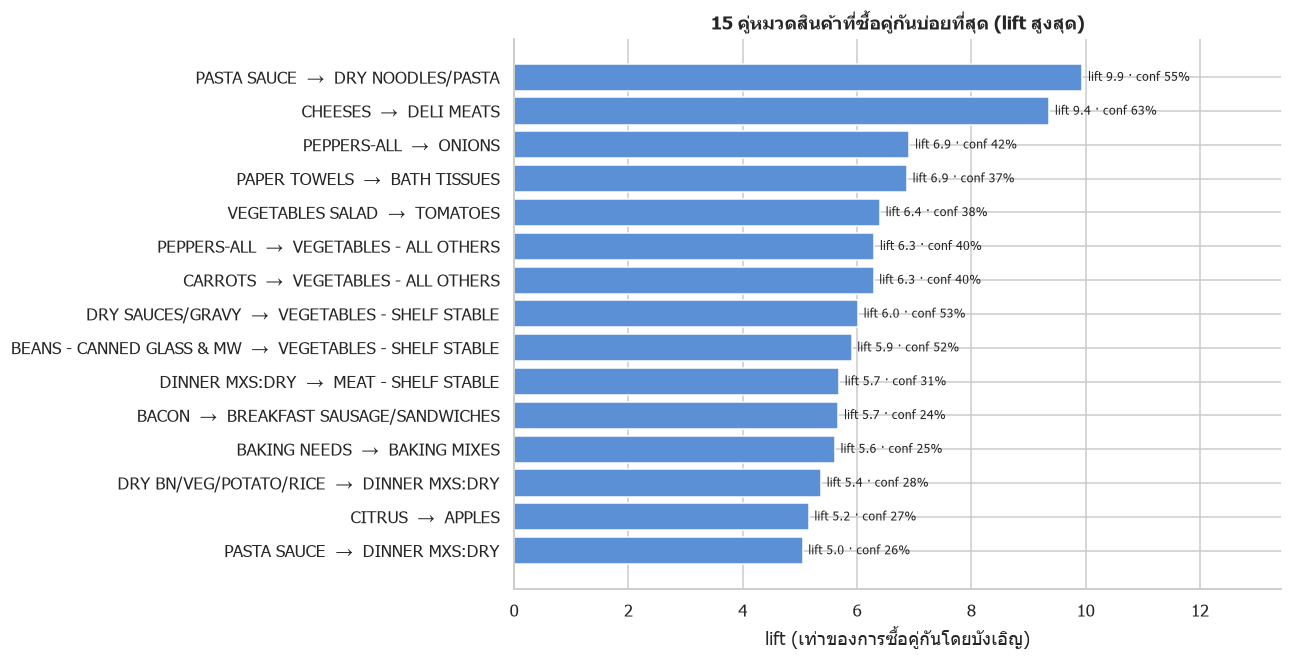

In [4]:
top = pairs.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.antecedent + "  →  " + top.consequent, top.lift, color=PRIMARY)
for i, (l, c) in enumerate(zip(top.lift, top.confidence)):
    ax.text(l + 0.1, i, f"lift {l:.1f} · conf {c:.0%}", va="center", fontsize=8)
ax.set_xlabel("lift (เท่าของการซื้อคู่กันโดยบังเอิญ)")
ax.set_title("15 คู่หมวดสินค้าที่ซื้อคู่กันบ่อยที่สุด (lift สูงสุด)")
ax.set_xlim(0, top.lift.max() * 1.35)
save(fig, "05_top_rules")
plt.show()

In [5]:
display(rules3[rules3.antecedent.str.contains(r"[+]") | rules3.consequent.str.contains(r"[+]")]
        .head(8)[["antecedent", "consequent", "support", "confidence", "lift"]])

,antecedent,consequent,support,confidence,lift
0,PASTA SAUCE,BEEF + DRY NOODLES/PASTA,0.01,0.31,12.09
1,BEEF + DRY NOODLES/PASTA,PASTA SAUCE,0.01,0.56,12.09
2,BEEF + PASTA SAUCE,DRY NOODLES/PASTA,0.01,0.62,11.32
3,DRY NOODLES/PASTA,BEEF + PASTA SAUCE,0.01,0.26,11.32
4,DRY NOODLES/PASTA + SOFT DRINKS,PASTA SAUCE,0.01,0.52,11.27
5,PASTA SAUCE,DRY NOODLES/PASTA + SOFT DRINKS,0.01,0.26,11.27
6,BAKED BREAD/BUNS/ROLLS + DRY NOODLES/PASTA,PASTA SAUCE,0.02,0.52,11.18
7,PASTA SAUCE,BAKED BREAD/BUNS/ROLLS + DRY NOODLES/PASTA,0.02,0.33,11.18


## 2. กฎเสถียรไหม? (หากฎจากสัปดาห์ 17–59 → ตรวจในสัปดาห์ 60–102)
ถ้ากฎเป็นแค่ความบังเอิญของช่วงเวลา lift ในช่วงหลังจะลดลงมาใกล้ 1 ใช้หลักเดียวกับ forward validation ใน notebook 03

คู่ที่หาได้จากช่วงแรก: 981 · ยังมี lift > 1.2 ในช่วงหลัง: 100% · correlation ของ lift: 0.99
lift เปลี่ยนเฉลี่ย (มัธยฐาน): -1.9%


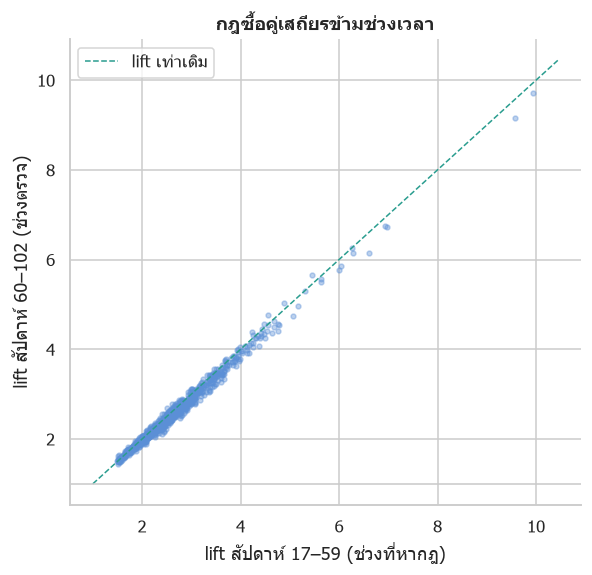

In [6]:
early = oh[(meta.WEEK_NO >= 17) & (meta.WEEK_NO <= 59)]
late = oh[meta.WEEK_NO >= 60]
pe = pair_table(mine_rules(early, min_support=0.01, max_len=2))
late_m = pd.DataFrame([rule_metrics(late, a, c) for a, c in zip(pe.antecedent, pe.consequent)])
pe["lift_late"], pe["conf_late"] = late_m["lift"].values, late_m["confidence"].values

stable_share = (pe.lift_late > 1.2).mean()
corr = pe[["lift", "lift_late"]].corr().iloc[0, 1]
print(f"คู่ที่หาได้จากช่วงแรก: {len(pe):,} · ยังมี lift > 1.2 ในช่วงหลัง: {stable_share:.0%} · correlation ของ lift: {corr:.2f}")
print(f"lift เปลี่ยนเฉลี่ย (มัธยฐาน): {(pe.lift_late / pe.lift - 1).median():+.1%}")

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(pe.lift, pe.lift_late, s=10, alpha=0.4, color=PRIMARY)
m = max(pe.lift.max(), pe.lift_late.max()) * 1.05
ax.plot([1, m], [1, m], color=ACCENT, lw=1, ls="--", label="lift เท่าเดิม")
ax.axhline(1, color=MUTED, lw=1)
ax.set_xlabel("lift สัปดาห์ 17–59 (ช่วงที่หากฎ)")
ax.set_ylabel("lift สัปดาห์ 60–102 (ช่วงตรวจ)")
ax.set_title("กฎซื้อคู่เสถียรข้ามช่วงเวลา")
ax.legend()
save(fig, "05_rule_stability")
plt.show()

## 3. แต่ละกลุ่มลูกค้าและช่วงพีคซื้อคู่กันต่างกันไหม?
วัด lift ของ 15 คู่หลักในตะกร้าของแต่ละกลุ่ม และในตะกร้าช่วง 15:00–19:59 เทียบช่วงอื่น

In [7]:
groups = {s: oh[meta.segment == s] for s in config.SEGMENT_ORDER}
groups["15-19 น."] = oh[meta.hour.between(15, 19)]
groups["นอกช่วงพีค"] = oh[~meta.hour.between(15, 19)]

top15 = pairs.head(15)
by_group = pd.DataFrame({
    g: [rule_metrics(b, a, c)["lift"] for a, c in zip(top15.antecedent, top15.consequent)]
    for g, b in groups.items()
}, index=top15.antecedent + " → " + top15.consequent)
print("จำนวนตะกร้า:", {g: f"{len(b):,}" for g, b in groups.items()})
by_group.round(1)

จำนวนตะกร้า: {'Champions': '172,846', 'Loyal': '37,817', 'At Risk': '37,730', 'Occasional': '5,958', '15-19 น.': '112,788', 'นอกช่วงพีค': '141,563'}


,Champions,Loyal,At Risk,Occasional,15-19 น.,นอกช่วงพีค
PASTA SAUCE → DRY NOODLES/PASTA,9.80,11.20,9.30,14.40,9.00,10.80
CHEESES → DELI MEATS,8.80,11.00,9.90,19.60,8.70,9.90
PEPPERS-ALL → ONIONS,6.90,6.90,7.00,9.10,6.30,7.50
PAPER TOWELS → BATH TISSUES,6.60,7.70,7.20,9.80,7.10,6.70
VEGETABLES SALAD → TOMATOES,6.40,6.30,6.60,7.20,5.90,6.90
PEPPERS-ALL → VEGETABLES - ALL OTHERS,6.30,6.10,6.40,8.60,5.90,6.70
CARROTS → VEGETABLES - ALL OTHERS,6.20,6.50,6.40,7.00,5.90,6.70
DRY SAUCES/GRAVY → VEGETABLES - SHELF STABLE,6.00,5.90,5.90,9.40,5.50,6.50
BEANS - CANNED GLASS & MW → VEGETABLES - SHELF STABLE,5.90,5.90,5.90,8.00,5.40,6.40
DINNER MXS:DRY → MEAT - SHELF STABLE,5.60,5.90,5.60,8.40,5.10,6.20


## 4. คู่สินค้าที่แนะนำสำหรับโปรขายคู่
คู่ที่ lift สูงแต่มีลูกค้าน้อยไม่คุ้มทำโปร จึงคัดคู่ที่ **lift ≥ 3 และ support ≥ 1%** แล้วเรียงตาม *โอกาสขายเพิ่ม*
- `baskets_A_not_B` = ตะกร้าที่ซื้อ A แต่ยังไม่ได้ซื้อ B (ใน 2 ปี) — กลุ่มเป้าหมายของโปร
- `avg_spend_B` = ยอดเฉลี่ยของหมวด B ในตะกร้าที่ซื้อ B
- `opportunity_$` = baskets_A_not_B × avg_spend_B (เพดานบน ถ้าทุกตะกร้าเพิ่ม B — ใช้กับ conversion rate ใน notebook 07)

In [8]:
opp = cross_sell_opportunity(tx, oh, pairs)
opp["opportunity_$"] = opp.baskets_A_not_B * opp.avg_spend_B
bundles = (opp[(opp.lift >= 3) & (opp.support >= 0.01)]
           .sort_values("opportunity_$", ascending=False).reset_index(drop=True))
bundles["rank"] = np.arange(1, len(bundles) + 1)
print(f"คู่ที่ผ่านเกณฑ์: {len(bundles)}")
bundles.head(10)[["antecedent", "consequent", "support", "confidence", "lift", "baskets_A_not_B", "avg_spend_B", "opportunity_$"]]

คู่ที่ผ่านเกณฑ์: 209


,antecedent,consequent,support,confidence,lift,baskets_A_not_B,avg_spend_B,opportunity_$
0,VEGETABLES - SHELF STABLE,BEEF,0.04,0.46,3.16,12280,8.51,"104,445.50"
1,FRZN MEAT/MEAT DINNERS,FROZEN PIZZA,0.03,0.32,3.47,15556,6.31,"98,165.91"
2,POTATOES,BEEF,0.03,0.44,3.08,8503,8.51,"72,320.85"
3,CHICKEN,BEEF,0.03,0.45,3.09,8331,8.51,"70,857.94"
4,DINNER MXS:DRY,FRZN MEAT/MEAT DINNERS,0.01,0.27,3.03,9692,7.06,"68,395.87"
5,DINNER MXS:DRY,CHICKEN,0.01,0.21,3.47,10571,6.27,"66,300.68"
6,FRZN VEGETABLE/VEG DSH,FRZN MEAT/MEAT DINNERS,0.01,0.28,3.12,9183,7.06,"64,803.89"
7,DRY BN/VEG/POTATO/RICE,CHICKEN,0.01,0.23,3.82,10265,6.27,"64,381.47"
8,DRY NOODLES/PASTA,BEEF,0.03,0.47,3.27,7401,8.51,"62,947.97"
9,CONVENIENT BRKFST/WHLSM SNACKS,FROZEN PIZZA,0.02,0.30,3.31,9769,6.31,"61,647.13"


In [9]:
opp.merge(bundles[["pair", "rank"]], on="pair", how="left").to_parquet(config.PROCESSED_DIR / "basket_rules.parquet")
print("saved basket_rules.parquet")

saved basket_rules.parquet


## สรุป Market Basket

| ผล | ตัวเลข |
|---|---|
| คู่หมวดที่ซื้อคู่กันบ่อยกว่าบังเอิญ (lift ≥ 1.5) | 980 คู่ จาก 254K ตะกร้า |
| คู่ที่แรงที่สุด | ซอสพาสต้า ↔ เส้นพาสต้า (lift 9.9 · 55% ของคนซื้อซอสซื้อเส้นด้วย) · ชีสเดลี่ ↔ เนื้อเดลี่ (9.4 · 63%) |
| ความเสถียร | คู่จากสัปดาห์ 17–59 **100% ยังมี lift > 1.2** ในสัปดาห์ 60–102 · correlation 0.99 · lift เปลี่ยนเฉลี่ย −2% |
| แยกกลุ่ม/ช่วงเวลา | lift ใกล้เคียงกันทุกกลุ่มและทุกช่วงเวลา (Occasional สูงกว่าเพราะฐานเล็ก) |

**ข้อค้นพบ**
1. **คนซื้อเป็น "มื้อ" ไม่ใช่เป็นชิ้น** — คู่ที่แรงคือชุดทำอาหาร: พาสต้า (เส้น + ซอส + เนื้อวัว), แซนด์วิช (ชีส + เนื้อเดลี่), ผัก (พริกหวาน + หอมใหญ่ + มะเขือเทศ), อาหารเช้า (เบคอน + ไส้กรอก)
2. **รูปแบบนี้เป็นโครงสร้าง ไม่ใช่ฤดูกาล** — กฎที่หาได้จากปีแรกใช้กับปีที่สองได้แทบเท่าเดิม → วางโปรขายคู่ล่วงหน้าได้
3. **ไม่ต้องแยกโปรขายคู่ตามกลุ่ม** — ทุกกลุ่มซื้อคู่แบบเดียวกัน · Champions มี ~68% ของตะกร้าทั้งหมด จึงได้ผลจากโปรขายคู่มากที่สุดโดยธรรมชาติ
4. **คู่ที่มีโอกาสขายเพิ่มสูงสุด** (lift ≥ 3, support ≥ 1%) ส่วนใหญ่มี **เนื้อสัตว์ (BEEF/CHICKEN) หรืออาหารแช่แข็งเป็นตัวเติม** เช่น ผักกระป๋อง → เนื้อวัว, อาหารแช่แข็ง → พิซซ่าแช่แข็ง

**นำไปใช้:** โปร "ชุดมื้อเย็น" ใน GROCERY + MEAT (เช่น ซื้อเส้น + ซอส ลดเนื้อวัว) ช่วง 15–19 น. · จัดวางสินค้าคู่ใกล้กัน · เสนอคูปองหมวด B ให้คนที่ซื้อ A เป็นประจำแต่ไม่เคยซื้อ B

**ข้อจำกัด:** lift บอกว่าซื้อคู่กัน ไม่ได้บอกว่าโปรจะทำให้ซื้อเพิ่ม (คนที่ซื้อคู่อยู่แล้วอาจได้ส่วนลดฟรี) → ต้องทดสอบเทียบ holdout ·
ระดับ COMMODITY ไม่มีข้อมูลกำไรของแต่ละหมวด